# Tugas UTS: Linear Regression & Logistic Regression

**Mata Kuliah:** Machine Learning

**Nama:** Diaz Azfiqo  
**NIM:** 241011400455  
**Kelas:** Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dua digit terakhir NIM adalah 55
RANDOM_STATE = 55
np.set_printoptions(precision=4, suppress=True)


In [2]:
# Implementasi train_test_split menggunakan NumPy (tanpa scikit-learn)
def train_test_split(X, y, test_size=0.2, random_state=0):
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# Model Linear Regression dengan Normal Equation
class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

# Model Linear Regression dengan Gradient Descent
class LinearRegressionGD:
    def __init__(self, learning_rate=0.001, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            error = X_b @ theta - y
            gradient = (2 / len(y)) * (X_b.T @ error)
            theta -= self.learning_rate * gradient
            self.loss_history.append(np.mean((X_b @ theta - y) ** 2))
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

# Fungsi evaluasi regresi
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / denominator if denominator != 0 else np.nan
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Model Logistic Regression dengan Gradient Descent
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        eps = 1e-12
        for _ in range(self.n_iterations):
            p = self.sigmoid(X_b @ theta)
            gradient = (X_b.T @ (p - y)) / len(y)
            theta -= self.learning_rate * gradient
            p_after = np.clip(self.sigmoid(X_b @ theta), eps, 1-eps)
            loss = -np.mean(y*np.log(p_after) + (1-y)*np.log(1-p_after))
            self.loss_history.append(loss)
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_b = np.c_[np.ones((len(X), 1)), X]
        return self.sigmoid(X_b @ np.r_[self.intercept_, self.coef_])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Metrik klasifikasi buatan sendiri
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    y_pred = np.asarray(y_pred).astype(int).reshape(-1)
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ])

def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true).reshape(-1) == np.asarray(y_pred).reshape(-1))

def precision_recall_f1(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return precision, recall, f1


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


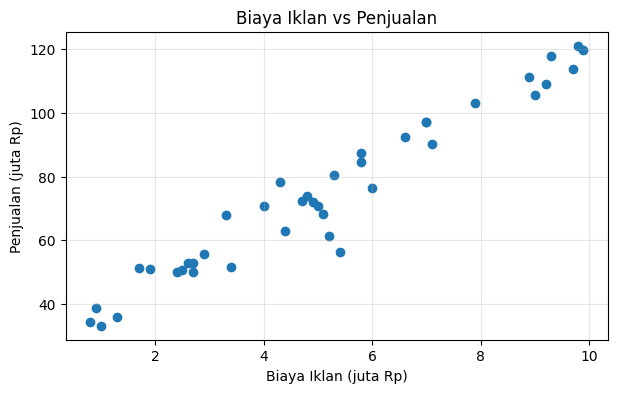

In [3]:
# Jawaban A1
ads = pd.read_csv('Ads_Data.csv')
display(ads.head())
print('Jumlah baris data:', len(ads))

X_ads = ads[['BiayaIklan']].to_numpy(dtype=float)  # shape (n, 1)
y_ads = ads['Penjualan'].to_numpy(dtype=float)
print('Shape X:', X_ads.shape)
print('Shape y:', y_ads.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X_ads[:, 0], y_ads)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
linear_model = LinearRegression().fit(X_train, y_train)
b = linear_model.intercept_
m = linear_model.coef_[0]
print(f'Intercept (b): {b:.4f}')
print(f'Koefisien (m): {m:.4f}')
print(f'Persamaan regresi: ŷ = {b:.4f} + ({m:.4f} × BiayaIklan)')


Intercept (b): 29.5113
Koefisien (m): 8.9558
Persamaan regresi: ŷ = 29.5113 + (8.9558 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Koefisien \(m = 8{,}9558\) berarti setiap kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar **Rp8,96 juta**, berdasarkan pola pada dataset. Intercept \(29{,}5113\) adalah prediksi penjualan saat biaya iklan Rp0 juta menurut garis model; ini merupakan titik potong matematis dan tidak selalu berarti kondisi bisnis nyata.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)
metrics_table = pd.DataFrame([
    {'Data': 'Training', **regression_metrics(y_train, y_train_pred)},
    {'Data': 'Testing', **regression_metrics(y_test, y_test_pred)}
]).set_index('Data')
display(metrics_table.round(4))


: 

**Jawaban A4 (analisis):**

Pada data testing, RMSE sebesar **6,2628 juta rupiah** berarti besar kesalahan prediksi tipikal sekitar Rp6,26 juta. Nilai \(R^2\) testing sebesar **0,9425** berarti model menjelaskan sekitar 94,25% variasi penjualan pada data testing. Hasil training (\(R^2=0,9378\), RMSE \(=5,9816\)) dan testing cukup berdekatan, sehingga pada pembagian data ini model terlihat baik dan tidak menunjukkan perbedaan performa yang besar. Namun, jumlah data hanya 40 sehingga evaluasi tambahan akan membantu memastikan kestabilannya.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/opt/pyvenv/lib/python3.13/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_534/2901085994.py:43: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean((X_b @ theta - y) ** 2))
/tmp/ipykernel_534/2901085994.py:41: RuntimeWarning: overflow encountered in matmul
  gradient = (2 / len(y)) * (X_b.T @ error)
/tmp/ipykernel_534/2901085994.py:42: RuntimeWarning: invalid value encountered in subtract
  theta -= self.learning_rate * gradient
/opt/pyvenv/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


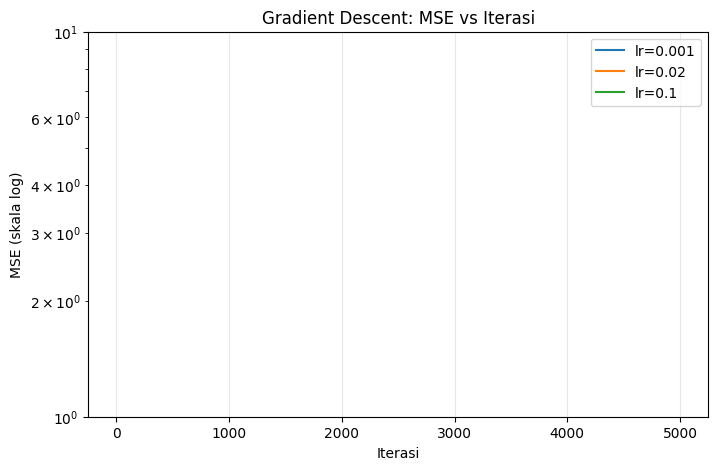

,Learning rate,Intercept,Koefisien,MSE akhir,Finite?
0,0.001,25.25546,9.60395,39.23723,True
1,0.020,29.51129,8.95576,35.77933,True
2,0.100,NaN,NaN,NaN,False


Normal equation: intercept=29.51129, koefisien=8.95576


In [7]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
rows = []
plt.figure(figsize=(8, 5))
for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model_gd
    rows.append({
        'Learning rate': lr,
        'Intercept': model_gd.intercept_,
        'Koefisien': model_gd.coef_[0],
        'MSE akhir': model_gd.loss_history[-1],
        'Finite?': bool(np.all(np.isfinite(model_gd.loss_history)))
    })
    losses = np.asarray(model_gd.loss_history)
    # Gunakan hanya loss positif dan finite agar grafik log tidak rusak
    valid = np.isfinite(losses) & (losses > 0)
    plt.plot(np.arange(1, len(losses)+1)[valid], losses[valid], label=f'lr={lr}')
plt.yscale('log')
plt.title('Gradient Descent: MSE vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('MSE (skala log)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(pd.DataFrame(rows).round(5))
print(f'Normal equation: intercept={linear_model.intercept_:.5f}, koefisien={linear_model.coef_[0]:.5f}')


**Jawaban A5 (analisis):**

Learning rate **0,001** masih terlalu lambat setelah 5.000 iterasi: koefisiennya sekitar 9,60395 dan intercept 25,25546, belum sedekat hasil Normal Equation. Learning rate **0,02** pas untuk data ini karena menghasilkan intercept 29,51129 dan koefisien 8,95576, hampir sama dengan Normal Equation. Learning rate **0,1** gagal konvergen (divergen), terlihat dari nilai parameter/loss menjadi `NaN` setelah nilai numerik membesar. Peringatan overflow berarti operasi menghasilkan angka di luar rentang yang dapat direpresentasikan; learning rate terlalu besar membuat pembaruan parameter melampaui solusi.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

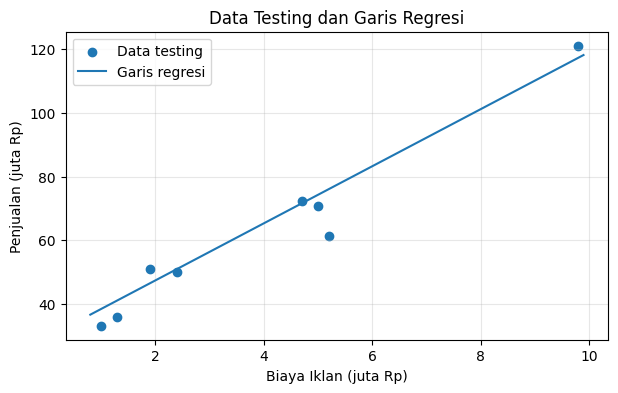

Biaya iklan Rp4.5 juta -> prediksi penjualan Rp69.81 juta
Biaya iklan Rp7 juta -> prediksi penjualan Rp92.20 juta
Biaya iklan Rp12 juta -> prediksi penjualan Rp136.98 juta


In [8]:
# Jawaban A6
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label='Data testing')
x_line = np.linspace(X_ads[:, 0].min(), X_ads[:, 0].max(), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], linear_model.predict(x_line), label='Garis regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = linear_model.predict(biaya_baru)
for biaya, pred in zip(biaya_baru[:, 0], prediksi_penjualan):
    print(f'Biaya iklan Rp{biaya:g} juta -> prediksi penjualan Rp{pred:.2f} juta')


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan Rp12 juta merupakan ekstrapolasi karena nilai tersebut berada di luar rentang biaya iklan pada dataset (maksimum Rp9,9 juta). Karena model belum diuji pada rentang itu, hasil Rp12 juta lebih tidak pasti dan hubungan linear mungkin tidak terus berlaku. Prediksi Rp4,5 juta dan Rp7 juta lebih dekat dengan rentang data yang diamati sehingga relatif lebih masuk akal, tetapi tetap merupakan perkiraan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah Bukan Spam (0): 35
Jumlah Spam (1): 25
Shape X: (60, 2)
Shape y: (60,)


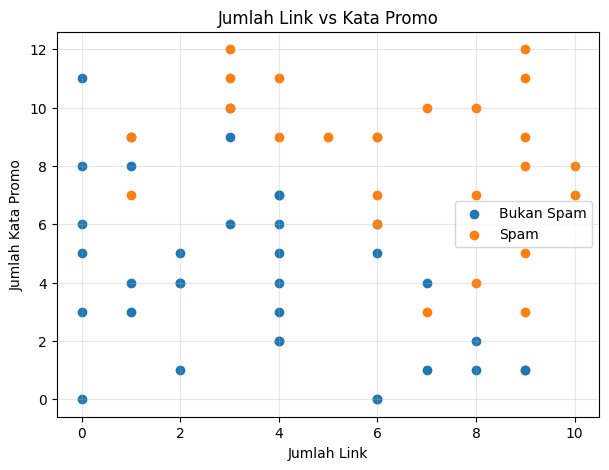

In [9]:
# Jawaban B1
email = pd.read_csv('Email_Data.csv')
display(email.head())
print('Jumlah Bukan Spam (0):', int((email['Spam'] == 0).sum()))
print('Jumlah Spam (1):', int((email['Spam'] == 1).sum()))

X_email = email[['JumlahLink', 'KataPromo']].to_numpy(dtype=float)
y_email = email['Spam'].to_numpy(dtype=int)
print('Shape X:', X_email.shape)
print('Shape y:', y_email.shape)

plt.figure(figsize=(7, 5))
for label, name in [(0, 'Bukan Spam'), (1, 'Spam')]:
    subset = email[email['Spam'] == label]
    plt.scatter(subset['JumlahLink'], subset['KataPromo'], label=name)
plt.title('Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
Intercept (b): -8.66094
Koefisien: [0.7275 0.7143]
P(Spam) = sigmoid(-8.66094 + (0.72747 × JumlahLink) + (0.71433 × KataPromo))


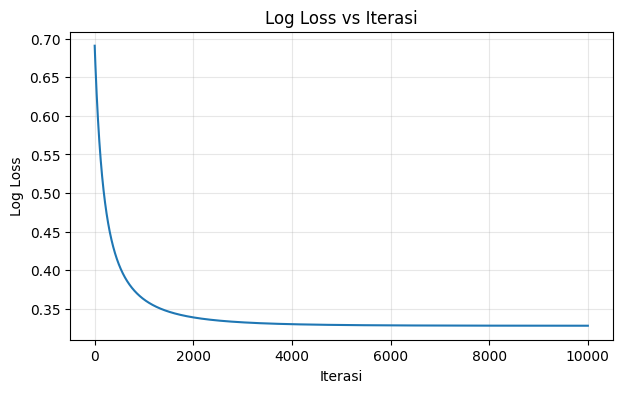

Log loss awal: 0.69082
Log loss akhir: 0.32822


In [10]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print('X_train:', X_train_email.shape, '| X_test:', X_test_email.shape)
print('Intercept (b):', round(log_model.intercept_, 5))
print('Koefisien:', log_model.coef_)
print(f'P(Spam) = sigmoid({log_model.intercept_:.5f} + ({log_model.coef_[0]:.5f} × JumlahLink) + ({log_model.coef_[1]:.5f} × KataPromo))')

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(log_model.loss_history)+1), log_model.loss_history)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(alpha=0.3)
plt.show()
print('Log loss awal:', round(log_model.loss_history[0], 5))
print('Log loss akhir:', round(log_model.loss_history[-1], 5))


**Jawaban B2 (analisis):**

Log loss turun dari **0,69082** pada awal training menjadi **0,32822** setelah 10.000 iterasi, sehingga model belajar membedakan kelas dan loss mengalami penurunan. Koefisien kedua fitur positif: semakin banyak link atau kata promo, probabilitas spam cenderung meningkat jika fitur lain tetap. Persamaan hasil model ditampilkan di atas. Grafik memperlihatkan penurunan loss yang kemudian melandai.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
proba_test = log_model.predict_proba(X_test_email)
pred_test = (proba_test >= 0.5).astype(int)
cm = confusion_matrix(y_test_email, pred_test)
precision, recall, f1 = precision_recall_f1(y_test_email, pred_test)
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm)
print(f'Accuracy : {accuracy_score(y_test_email, pred_test):.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall   : {recall:.4f}')
print(f'F1-score : {f1:.4f}')


Confusion matrix [[TN, FP], [FN, TP]]:
[[6 0]
 [0 9]]
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


**Jawaban B3 (analisis):**

**FP (False Positive)** adalah email bukan spam yang keliru ditandai sebagai spam. **FN (False Negative)** adalah email spam yang keliru dianggap bukan spam dan masuk ke kotak masuk. Pada data testing ini, confusion matrix menghasilkan TN=6, FP=0, FN=0, dan TP=9, sehingga semua 15 email terklasifikasi benar (akurasi, precision, recall, dan F1 = 1,00). Secara umum, FN dapat merugikan karena spam lolos ke kotak masuk, sedangkan FP juga berisiko karena email penting dapat masuk folder spam. Hasil sempurna pada 15 data testing ini belum menjamin kinerja yang sama pada email baru.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: -8.66094 + (0.72747)x1 + (0.71433)x2 = 0
x2 = -(-8.66094 + (0.72747)x1) / (0.71433)


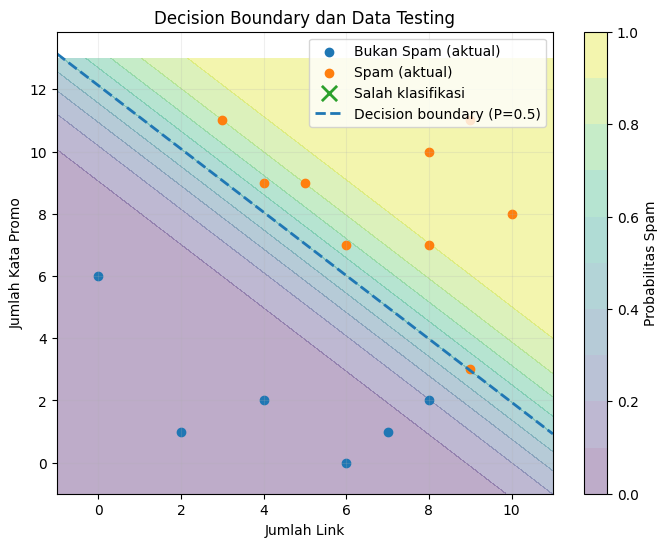

Data testing yang salah diklasifikasikan:
Tidak ada pada threshold 0.5.


In [12]:
# Jawaban B4
b = log_model.intercept_
m1, m2 = log_model.coef_
print(f'Decision boundary: {b:.5f} + ({m1:.5f})x1 + ({m2:.5f})x2 = 0')
if abs(m2) > 1e-12:
    print(f'x2 = -({b:.5f} + ({m1:.5f})x1) / ({m2:.5f})')
else:
    print('Koefisien x2 mendekati nol, sehingga boundary tidak dapat ditulis sebagai x2 = ... dengan pembagian stabil.')

x_min, x_max = X_email[:, 0].min()-1, X_email[:, 0].max()+1
y_min, y_max = X_email[:, 1].min()-1, X_email[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = log_model.predict_proba(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), alpha=0.35)
plt.colorbar(label='Probabilitas Spam')
for label, name in [(0, 'Bukan Spam'), (1, 'Spam')]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], label=f'{name} (aktual)')
wrong = pred_test != y_test_email
plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], marker='x', s=120, linewidths=2, label='Salah klasifikasi')
if abs(m2) > 1e-12:
    x_vals = np.linspace(x_min, x_max, 200)
    y_boundary = -(b + m1*x_vals)/m2
    plt.plot(x_vals, y_boundary, linestyle='--', linewidth=2, label='Decision boundary (P=0.5)')
plt.title('Decision Boundary dan Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print('Data testing yang salah diklasifikasikan:')
if np.any(wrong):
    wrong_rows = pd.DataFrame(X_test_email[wrong], columns=['JumlahLink', 'KataPromo'])
    wrong_rows['Aktual Spam'] = y_test_email[wrong]
    wrong_rows['Prediksi Spam'] = pred_test[wrong]
    wrong_rows['Probabilitas Spam'] = proba_test[wrong]
    display(wrong_rows)
else:
    print('Tidak ada pada threshold 0.5.')


**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (proba_test >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    cm_t = confusion_matrix(y_test_email, pred)
    p_t, r_t, f1_t = precision_recall_f1(y_test_email, pred)
    tn, fp, fn, tp = cm_t.ravel()
    threshold_rows.append({
        'Threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Precision': p_t, 'Recall': r_t, 'Accuracy': accuracy_score(y_test_email, pred)
    })
display(pd.DataFrame(threshold_rows).round(4))


,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy
0,0.3,6,0,0,9,1.0,1.0000,1.0
1,0.5,6,0,0,9,1.0,1.0000,1.0
2,0.7,6,0,3,6,1.0,0.6667,0.8


**Jawaban B5 (analisis):**

Pada data testing ini, threshold **0,3** dan **0,5** menghasilkan confusion matrix yang sama (TN=6, FP=0, FN=0, TP=9). Threshold **0,7** menaikkan precision tetap 1,00 tetapi recall turun menjadi 0,6667 karena 3 email spam menjadi FN. Secara umum, threshold lebih rendah membuat model lebih mudah memberi label spam dan cenderung meningkatkan recall, sementara threshold lebih tinggi membuat model lebih ketat dan dapat mengurangi recall. Untuk tugas ini dipilih threshold **0,3** karena pada data testing hasilnya sama baiknya dengan 0,5 dan memprioritaskan agar spam tidak lolos; keputusan ini tetap perlu diuji pada data yang lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
# Pilih threshold berdasarkan eksperimen B5: 0.3 untuk memprioritaskan recall.
CHOSEN_THRESHOLD = 0.3
new_emails = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})
new_X = new_emails[['JumlahLink', 'KataPromo']].to_numpy(dtype=float)
new_emails['Probabilitas Spam'] = log_model.predict_proba(new_X)
new_emails['Prediksi (0=Bukan Spam, 1=Spam)'] = (new_emails['Probabilitas Spam'] >= CHOSEN_THRESHOLD).astype(int)
new_emails['Kelas Prediksi'] = np.where(new_emails['Prediksi (0=Bukan Spam, 1=Spam)'] == 1, 'Spam', 'Bukan Spam')
display(new_emails.round(4))
print('Threshold yang digunakan:', CHOSEN_THRESHOLD)


,Email,JumlahLink,KataPromo,Probabilitas Spam,"Prediksi (0=Bukan Spam, 1=Spam)",Kelas Prediksi
0,E1,1,2,0.0015,0,Bukan Spam
1,E2,5,6,0.3235,1,Spam
2,E3,9,10,0.9935,1,Spam
3,E4,2,11,0.6574,1,Spam


Threshold yang digunakan: 0.3


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena hasil akhirnya digunakan untuk menentukan kelas, misalnya spam atau bukan spam. Model menghitung skor dari kombinasi fitur, kemudian fungsi sigmoid mengubah skor itu menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:**

Normal Equation menghitung parameter regresi secara langsung melalui operasi matriks sehingga tidak perlu menentukan learning rate atau jumlah iterasi. Gradient Descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih berguna ketika data atau jumlah fitur sangat besar sehingga perhitungan matriks pada Normal Equation menjadi mahal.

**Jawaban C3:**

Data training digunakan untuk mempelajari parameter model, sedangkan data testing digunakan untuk mengukur kemampuan model pada data yang belum pernah dilihat. Jika evaluasi hanya dilakukan pada data training, hasilnya dapat terlihat bagus karena model sudah menyesuaikan diri dengan data tersebut. Overfitting terjadi ketika model terlalu mengikuti pola atau noise pada data training sehingga performanya menurun pada data baru.

**Jawaban C4:**

Linear Regression menghasilkan nilai numerik kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara prediksi dan nilai sebenarnya. Logistic Regression menghasilkan probabilitas untuk kelas, sehingga log loss menilai seberapa tepat probabilitas tersebut terhadap label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin tetapi prediksinya salah.

**Jawaban C5:**

Hasil dapat berbeda jika pembagian data training dan testing menggunakan random_state yang berbeda. Pembagian data mengubah contoh yang digunakan untuk melatih model, sehingga koefisien dan metrik evaluasi juga dapat berubah. Hasil juga dipengaruhi oleh learning rate, jumlah iterasi, inisialisasi parameter, dan detail implementasi algoritma.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus: bandingkan dengan scikit-learn
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
    from sklearn.metrics import accuracy_score as sk_accuracy, confusion_matrix as sk_cm, mean_squared_error, r2_score

    sk_linear = SklearnLinearRegression().fit(X_train, y_train)
    sk_y_pred = sk_linear.predict(X_test)
    print('LINEAR REGRESSION')
    print('Normal Equation manual - intercept:', linear_model.intercept_, 'koefisien:', linear_model.coef_)
    print('scikit-learn - intercept:', sk_linear.intercept_, 'koefisien:', sk_linear.coef_)
    print('R2 testing manual:', regression_metrics(y_test, y_test_pred)['R2'])
    print('R2 testing scikit-learn:', r2_score(y_test, sk_y_pred))

    # C diset sangat besar agar regularisasi L2 minimal; solver dipilih untuk optimisasi yang stabil.
    sk_log = SklearnLogisticRegression(C=1e6, max_iter=10000, solver='lbfgs')
    sk_log.fit(X_train_email, y_train_email)
    sk_pred = sk_log.predict(X_test_email)
    print('\nLOGISTIC REGRESSION')
    print('Manual - intercept:', log_model.intercept_, 'koefisien:', log_model.coef_)
    print('scikit-learn - intercept:', sk_log.intercept_[0], 'koefisien:', sk_log.coef_[0])
    print('Accuracy testing manual:', accuracy_score(y_test_email, pred_test))
    print('Accuracy testing scikit-learn:', sk_accuracy(y_test_email, sk_pred))
    print('Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:')
    print(sk_cm(y_test_email, sk_pred, labels=[0, 1]))
except ImportError:
    print('scikit-learn belum tersedia. Bagian bonus dapat dijalankan di lingkungan yang memiliki scikit-learn.')


LINEAR REGRESSION
Normal Equation manual - intercept: 29.511293625258986 koefisien: [8.9558]
scikit-learn - intercept: 29.511293625259214 koefisien: [8.9558]
R2 testing manual: 0.9424575012326584
R2 testing scikit-learn: 0.9424575012326576

LOGISTIC REGRESSION
Manual - intercept: -8.660937809501087 koefisien: [0.7275 0.7143]
scikit-learn - intercept: -8.812297264941344 koefisien: [0.7409 0.7268]
Accuracy testing manual: 1.0
Accuracy testing scikit-learn: 1.0
Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:
[[6 0]
 [0 9]]


**Jawaban Bonus (analisis):**

Hasil Linear Regression manual dan scikit-learn seharusnya sangat dekat karena keduanya mencari solusi kuadrat terkecil. Hasil Logistic Regression dapat berbeda karena scikit-learn secara default menggunakan regularisasi L2, sedangkan implementasi manual pada notebook ini tidak memakai regularisasi. Nilai `C` yang besar memperlemah regularisasi pada scikit-learn, tetapi perbedaan toleransi optimisasi dan jumlah iterasi masih dapat menghasilkan selisih kecil.